# Risk class classification: training

Train and tune several classifiers for `risk_class`, then save them for `evaluation.ipynb`.

Tuning strategy (keeps the whole notebook in the ~10 minute range):

1. hyper-parameters are searched with cross-validation on a **stratified subsample** of the training set (`TUNE_SIZE` rows);
2. the best parameters are then **refit on the full training set**;
3. every fitted model, its parameters and the test-set indices are saved to `MODELS_DIR`.

The held-out test set is **not** used here. Scoring and confusion matrices live in `evaluation.ipynb`.

In [21]:
import json
import time
import warnings

import numpy as np
import pandas as pd

from pathlib import Path

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import recall_score, make_scorer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import joblib
import matplotlib.pyplot as plt

In [22]:
PROJECT_ROOT = Path.cwd().parent.parent
DATA_DIR = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "prediction" / "ml" / "models"

RANDOM_STATE = 156543894

TUNE_SIZE = 20_000
N_FOLDS = 3               
TUNING_METRIC = "accuracy"
SVM_MAX_TRAIN = 40_000

T_START = time.perf_counter()

warnings.filterwarnings("ignore", message="'n_jobs' has no effect")  # LogisticRegression deprecation noise

DATA_DIR

PosixPath('/home/hp/Documents/School/S4a/Intelligence Artificielle/Projet/hospital/data')

In [23]:
df = pd.read_csv(DATA_DIR / "patient_preprocessed.csv")

df = df.drop(columns=["PATIENT"])

df.describe()

,INCOME,prior_urgent_visits,prior_visits,prior_conditions,prior_medications,prior_procedures,prior_immunizations,prior_allergies,prior_careplans,prior_imaging_studies,...,obs_Triglyceride_[Mass_volume]_in_Serum_or_Plasma,obs_Urea_nitrogen_[Mass_volume]_in_Blood,age_years,age_months,gender_m,gender_f,race,is_hispanic,risk_score,risk_class
count,103189.000000,103189.000000,103189.000000,103189.000000,103189.000000,103189.000000,103189.000000,103189.000000,103189.000000,103189.000000,...,103189.000000,103189.000000,103189.000000,103189.000000,103189.000000,103189.000000,103189.000000,103189.000000,103189.000000,103189.000000
mean,112113.476068,6.053543,59.886044,26.084525,53.772708,89.309112,2.030304,0.838345,2.998362,57.021000,...,141.298747,13.579409,51.383335,4.967458,0.501042,0.498958,0.316836,0.108209,0.220769,0.233048
std,166138.245441,11.803469,75.014857,22.928501,84.933717,110.655046,2.288840,2.298748,1.887940,652.816316,...,39.564772,2.996758,24.795448,3.500996,0.500001,0.500001,0.760076,0.310646,0.148827,0.601871
min,101.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,100.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.050600,0.000000
25%,27891.000000,0.000000,12.000000,11.000000,3.000000,13.000000,1.000000,0.000000,2.000000,0.000000,...,125.200000,12.300000,33.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.141200,0.000000
50%,61855.000000,2.000000,25.000000,20.000000,13.000000,41.000000,2.000000,0.000000,3.000000,1.000000,...,133.600000,13.500000,56.000000,5.000000,1.000000,0.000000,0.000000,0.000000,0.183900,0.000000
75%,118458.000000,6.000000,79.000000,34.000000,66.000000,127.000000,3.000000,0.000000,4.000000,4.000000,...,145.300000,15.400000,69.000000,8.000000,1.000000,1.000000,0.000000,0.000000,0.231800,0.000000
max,997562.000000,165.000000,455.000000,174.000000,685.000000,695.000000,25.000000,15.000000,11.000000,15289.000000,...,553.300000,20.000000,110.000000,11.000000,1.000000,1.000000,5.000000,1.000000,1.000000,3.000000


## Train / test split

In [24]:
X = df.drop(columns=["risk_score", "risk_class"])
y = df["risk_class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(X_train.shape, X_test.shape)
y_train.value_counts(normalize=True).round(3)

(82551, 55) (20638, 55)


risk_class
0    0.842
1    0.099
2    0.043
3    0.016
Name: proportion, dtype: float64

## Tuning setup

`X_tune` / `y_tune` is the stratified subsample used by every hyper-parameter search.
All searches report the same four metrics; `TUNING_METRIC` decides which parameters win.
`f1_macro` weights every class equally, so the rare high-risk classes matter as much as class 0,
while still penalising models that flag everyone as high risk. Tuning on `recall_macro` instead
pushes every model to `class_weight="balanced"` (critical recall ~0.8 but accuracy drops to ~0.6);
tuning on `accuracy` does the opposite. Change the constant to try either.

In [25]:
X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train,
    train_size=TUNE_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_train,
)

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "recall_macro": "recall_macro",
    "critical_recall": make_scorer(recall_score, labels=[3], average="macro", zero_division=0),
}

print(X_tune.shape)

(20000, 55)


In [26]:
models, best_params = {}, {}


def tune(estimator, param_grid, n_iter=None):
    """Search hyper-parameters on the tuning subsample with cross-validation.

    n_iter=None runs the whole grid (GridSearchCV), otherwise n_iter random
    combinations are tried (RandomizedSearchCV). Nothing is refit here: the
    winning parameters are returned and fitted on the full training set by `fit_final`.
    """
    common = dict(scoring=scoring, refit=False, cv=cv, n_jobs=-1, verbose=1)
    if n_iter is None:
        search = GridSearchCV(estimator, param_grid, **common)
    else:
        search = RandomizedSearchCV(estimator, param_grid, n_iter=n_iter, random_state=RANDOM_STATE, **common)

    t0 = time.perf_counter()
    search.fit(X_tune, y_tune)
    cv_results = pd.DataFrame(search.cv_results_)

    best = cv_results.loc[cv_results[f"mean_test_{TUNING_METRIC}"].idxmax()]
    print(f"search done in {time.perf_counter() - t0:.0f} s")
    print(f"best CV {TUNING_METRIC}: {best[f'mean_test_{TUNING_METRIC}']:.4f} "
          f"(accuracy {best['mean_test_accuracy']:.4f}, f1_macro {best['mean_test_f1_macro']:.4f})")
    print("best params:", best["params"])
    return best["params"], cv_results


def fit_final(estimator, params, X=X_train, y=y_train):
    """Fit a fresh copy of the estimator with the chosen parameters on the (full) training set."""
    model = clone(estimator).set_params(**params)
    # the search ran many single-threaded fits in parallel; the single final fit can use every core
    for name in model.get_params():
        if name == "n_jobs" or name.endswith("__n_jobs"):
            model.set_params(**{name: -1})

    t0 = time.perf_counter()
    model.fit(X, y)
    print(f"final fit on {len(X):,} rows in {time.perf_counter() - t0:.0f} s")
    return model


def register(name, model, params):
    """Keep a fitted model and its chosen parameters for the saving step."""
    models[name], best_params[name] = model, params

## KNN

In [27]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = make_pipeline(StandardScaler(), KNeighborsClassifier())

knn_params = {
    "kneighborsclassifier__n_neighbors": range(1, 51),
    "kneighborsclassifier__weights": ["uniform", "distance"],
}

knn_best, knn_cv = tune(knn_model, knn_params)

Fitting 3 folds for each of 100 candidates, totalling 300 fits
search done in 21 s
best CV accuracy: 0.8486 (accuracy 0.8486, f1_macro 0.3792)
best params: {'kneighborsclassifier__n_neighbors': 17, 'kneighborsclassifier__weights': 'uniform'}


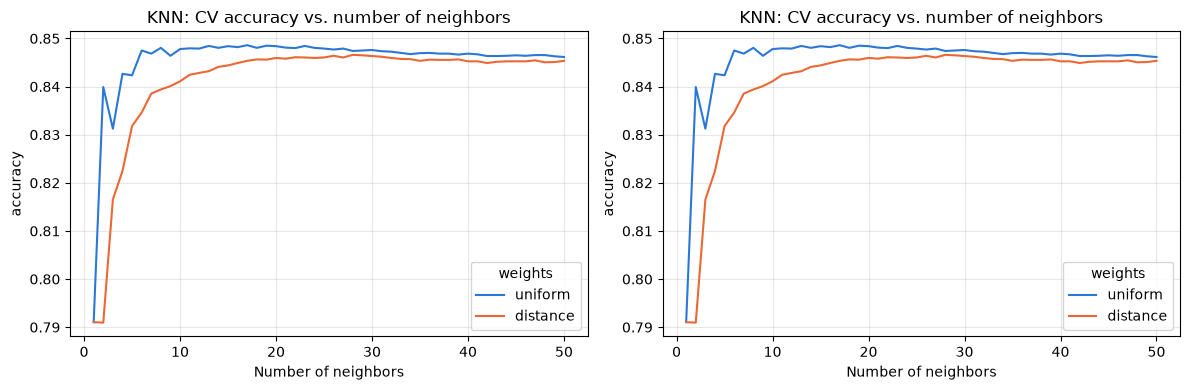

In [28]:
k_col = "param_kneighborsclassifier__n_neighbors"
w_col = "param_kneighborsclassifier__weights"
colors = {"uniform": "#2a78d6", "distance": "#eb6834"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["accuracy", TUNING_METRIC]):
    for weights, color in colors.items():
        sub = knn_cv[knn_cv[w_col] == weights].sort_values(k_col)
        ax.plot(sub[k_col].astype(int), sub[f"mean_test_{metric}"], color=color, linewidth=1.5, label=weights)
    ax.set_title(f"KNN: CV {metric} vs. number of neighbors")
    ax.set_xlabel("Number of neighbors")
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend(title="weights")

plt.tight_layout()
plt.show()

In [29]:
knn_model = fit_final(knn_model, knn_best)

register("knn", knn_model, knn_best)

final fit on 82,551 rows in 0 s


## Logistic Regression

In [30]:
from sklearn.linear_model import LogisticRegression

lr_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

lr_params = {
    "logisticregression__C": [0.01, 0.1, 1, 10, 100],
    "logisticregression__class_weight": [None, "balanced"],
}

lr_best, lr_cv = tune(lr_model, lr_params)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
search done in 2 s
best CV accuracy: 0.8464 (accuracy 0.8464, f1_macro 0.3862)
best params: {'logisticregression__C': 0.1, 'logisticregression__class_weight': None}


In [31]:
lr_model = fit_final(lr_model, lr_best)

register("lr", lr_model, lr_best)

final fit on 82,551 rows in 3 s


## Random Forest

In [32]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=RANDOM_STATE)

rf_params = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 0.5],
    "class_weight": [None, "balanced", "balanced_subsample"],
    "criterion": ["gini", "entropy"],
}

rf_best, rf_cv = tune(rf_model, rf_params, n_iter=30)

Fitting 3 folds for each of 30 candidates, totalling 90 fits
search done in 78 s
best CV accuracy: 0.8513 (accuracy 0.8513, f1_macro 0.4081)
best params: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 10, 'criterion': 'entropy', 'class_weight': None}


In [33]:
rf_model = fit_final(rf_model, rf_best)

register("rf", rf_model, rf_best)

final fit on 82,551 rows in 1 s


## SVM

An RBF `SVC` costs roughly O(n²) to train, so the final model is fit on at most `SVM_MAX_TRAIN`
stratified rows of the training set (raise the constant if you have time to spare).
The linear kernel is left out: it is even slower on this many rows and the logistic regression
above already covers the linear case.

In [34]:
from sklearn.svm import SVC

svm_model = make_pipeline(StandardScaler(), SVC(kernel="rbf", cache_size=500))

svm_params = {
    "svc__C": [0.3, 1, 3, 10, 30],
    "svc__gamma": ["scale", 0.01, 0.03, 0.1],
    "svc__class_weight": [None, "balanced"],
}

svm_best, svm_cv = tune(svm_model, svm_params, n_iter=16)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
search done in 195 s
best CV accuracy: 0.8495 (accuracy 0.8495, f1_macro 0.4038)
best params: {'svc__gamma': 0.01, 'svc__class_weight': None, 'svc__C': 3}


In [35]:
if len(X_train) > SVM_MAX_TRAIN:
    X_svm, _, y_svm, _ = train_test_split(
        X_train, y_train, train_size=SVM_MAX_TRAIN, random_state=RANDOM_STATE, stratify=y_train
    )
else:
    X_svm, y_svm = X_train, y_train

svm_model = fit_final(svm_model, {**svm_best, "svc__cache_size": 2000}, X=X_svm, y=y_svm)

register("svm", svm_model, svm_best)

final fit on 40,000 rows in 51 s


## Naive Bayes

In [36]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_params = {"var_smoothing": np.logspace(-12, 0, 13)}

nb_best, nb_cv = tune(nb_model, nb_params)

Fitting 3 folds for each of 13 candidates, totalling 39 fits
search done in 1 s
best CV accuracy: 0.8423 (accuracy 0.8423, f1_macro 0.2286)
best params: {'var_smoothing': np.float64(1.0)}


In [37]:
nb_model = fit_final(nb_model, nb_best)

register("nb", nb_model, nb_best)

final fit on 82,551 rows in 0 s


## Gradient Boosting

`HistGradientBoostingClassifier` is scikit-learn's fast gradient boosting implementation.
It is usually the strongest classical model on tabular data and trains in seconds, so it is included in the comparison.

In [38]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_model = HistGradientBoostingClassifier(random_state=RANDOM_STATE)

hgb_params = {
    "learning_rate": [0.03, 0.05, 0.1, 0.2],
    "max_iter": [100, 200, 400],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [10, 20, 50],
    "l2_regularization": [0, 0.1, 1.0],
    "class_weight": [None, "balanced"],
}

hgb_best, hgb_cv = tune(hgb_model, hgb_params, n_iter=20)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
search done in 12 s
best CV accuracy: 0.8513 (accuracy 0.8513, f1_macro 0.4317)
best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 400, 'learning_rate': 0.03, 'l2_regularization': 0.1, 'class_weight': None}


In [39]:
hgb_model = fit_final(hgb_model, hgb_best)

register("hgb", hgb_model, hgb_best)

final fit on 82,551 rows in 6 s


# Save models

In [40]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)

for name, model in models.items():
    path = MODELS_DIR / f"{name}_model.joblib"
    joblib.dump(model, path, compress=3)
    print("saved", path.relative_to(PROJECT_ROOT))

with open(MODELS_DIR / "best_params.json", "w") as f:
    json.dump(best_params, f, indent=2, default=str)

# Same held-out rows for evaluation.ipynb, whatever happens to the CSV or the split later.
# (df keeps its default RangeIndex, so these are row labels of patient_preprocessed.csv.)
with open(MODELS_DIR / "split.json", "w") as f:
    json.dump({
        "random_state": RANDOM_STATE,
        "test_index": [int(i) for i in X_test.index],
    }, f)

print(f"\ntotal notebook time: {(time.perf_counter() - T_START) / 60:.1f} min")

saved prediction/ml/models/knn_model.joblib
saved prediction/ml/models/lr_model.joblib
saved prediction/ml/models/rf_model.joblib
saved prediction/ml/models/svm_model.joblib
saved prediction/ml/models/nb_model.joblib
saved prediction/ml/models/hgb_model.joblib

total notebook time: 6.2 min
